# Activité Pratique N°2 — Modèles génératifs avec PyTorch

# Partie I — Modèle discriminatif

## 0. Préparation de l'environnement

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch:", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

PyTorch: 2.14.1+cu126
Device: cuda


## 1. Jeu de données MNIST

Images de chiffres manuscrits de 28 × 28 = 784 pixels, chacune avec un label entre 0 et 9.
Le même dataset sert à comparer les différents modèles des parties I à V.

In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train:", len(train_dataset))
print("Test:", len(test_dataset))

Train: 60000
Test: 10000


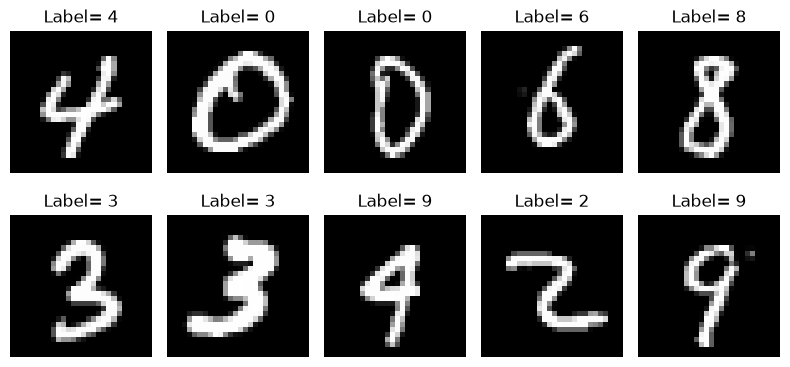

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label= {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Classification : apprendre $P(y|x)$

Un classifieur reçoit une entrée $x$ et prédit une classe $\hat y$ : il apprend approximativement $P(y|x)$.
Nous utilisons un réseau entièrement connecté simple.

In [4]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)
classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

### Fonction de perte

Pour une classification multi-classe : $\mathcal{L}_{class} = CrossEntropy(\hat y, y)$.
Le label est donc indispensable.

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(classifier.parameters(), lr=1e-3)

In [6]:
def train_classifier(model, loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs}-"
            f"Loss={total_loss/len(loader):.4f}"
        )
train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3-Loss=0.4169
Epoch 2/3-Loss=0.1931
Epoch 3/3-Loss=0.1385


In [7]:
def evaluate_classifier(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct/total

accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100*accuracy:.2f}%")

Accuracy = 96.37%


### Une autre façon d'évaluer le modèle : `torcheval`

In [8]:
from torcheval.metrics import MulticlassAccuracy

@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    device = next(model.parameters()).device

    metric = MulticlassAccuracy(device=device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        metric.update(logits, y)

    return metric.compute().item()


accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100 * accuracy:.2f}%")

c:\Users\user\Desktop\5IAD G1 BENHAYOUN SADAFI Mohamed, emsi, matiere ia multimodale\Activité Pratique N°1 - Mise en oeuvre du Framework PyTorch\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Accuracy = 96.37%


### Conclusion

Le réseau apprend ici $x \rightarrow y$ : il **discrimine** les classes. Il ne sait pas générer une
nouvelle image de chiffre. Les parties suivantes passent aux modèles **génératifs**.